# Chapter 08 제출 답안 — 작은 데이터 분석 프로젝트 완성하기

## 제출 정보
- 이름: 이성민
- GitHub ID: minilee0307-dot
- 작성·실행일: 2026-10-27
- 분석 기준일: **2026-10-08** — Chapter 06·07과 같은 범위로 비교하기 위해 고정했다.
- 최종 Notebook URL: https://github.com/minilee0307-dot/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb
- 실습 상태: **COMPLETE** — 저장된 전체 실행 결과와 최종 Validation을 확인했다.
- GitHub 표시·eTL 접수 상태: **COMPLETE** — 2026-10-27 GitHub 본문·저장 출력·표·그래프3개·상대 이미지 링크를 확인했고, eTL에서 **2026-10-27 14:58 (Asia/Seoul) 제출됨**과 최종 Notebook 파일 URL 접수를 확인했다. 온라인 확인과 제출은 Codex의 도움을 받았다.

### 이번 프로젝트의 결론

원본 CSV 4개에서 다시 시작해 전처리·키·병합·계산식·날짜·총합·공개 고객 결과를 검증했다. 최종 금액 범위는 **completed·유효 주문일·기준일 이하**인 421상세, 금액이 있는 175주문, 구매고객 96명이다. 날짜·상태 조건에 맞는 176주문 중 상세가 남지 않은 1주문은 평균 분모에서 제외했다. 관측 거래일은 **2025-07-02~2026-08-28, 양 끝 포함**이다. 남은 상세의 `quantity × unit_price` 합 **134,523,000원**이 원본 독립 계산 및 카테고리·월·고객 집계와 일치했다.

초기에는 날짜 결측 완료 상세 6행·1,903,000원 때문에 날짜와 월별 총합 검증이 FAIL이었다. 기준일 이후 3행·909,000원도 별도 영향으로 기록하고, 모든 금액 집계에 같은 제외 기준을 적용한 후 다시 검증했다. 원본 날짜를 복원했거나 이상값이 없다고 주장하지 않았다. 일부 상세가 격리된 주문 18건이 남아 있으므로 이 금액은 원래 전체 청구액이나 회계상 순매출·이익이 아니다.

### 기준 자료와 AI 활용

2026-10-27 확인한 [eTL Chapter 08 안내](https://myetl.snu.ac.kr/courses/310975/assignments/387495), 공식 커밋 `6105f42bd8294cb364dde6dcc2fee71c32e14794`의 [Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/notebooks/ch08_midterm_project.ipynb), [실습 가이드](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/practice/chapter08/chapter08.md), [답안 양식](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/practice/chapter08/templates/chapter08_assignment.md)을 따랐다. 공식 Notebook을 바탕으로 기존 저장소의 전처리 함수에 맞춰 호출을 조정했다.

코드 작성·실행·독립 검토·문장 정리에 Codex의 도움을 받았다. 학생이 별도로 손으로 재계산했거나 모든 코드를 이미 이해했다고 기록하지 않았다. 아래 실제 표·검증 결과·그래프가 Evidence이며 화면 캡처를 모방해 만들지 않았다. 이 과제는 쇼핑몰 합성 데이터 종합 실습으로, 별도의 χ-separation 뇌지도 자유 주제 프로젝트와 구분한다.

## 1. 프로젝트 질문과 완료 기준

| 분석 질문 | 분석 대상·범위 | 데이터와 지표 | 완료 기준 |
| --- | --- | --- | --- |
| 카테고리별 완료 주문 상세 금액은 어떻게 다른가? | 공통 completed·유효일·기준일 이하의 421상세 | orders, order_items, products; 금액 합, 수량 합, 같은 전체 금액 대비 비중 | 원본 독립 합계와 카테고리 합계가 같고 각 막대 값이 집계표와 같음 |
| 월별 금액과 주문 수는 어떻게 달라지는가? | 같은 금액 모집단, 2025-07~2026-08의 월 | 금액 합, 고유 order_id 수, 남은 상세 기준 평균 주문금액 | 월 합계가 source와 같고 날짜 오류·순서·누락 월과 실제0을 점검함 |
| 금액 상위 고객의 구매 횟수와 평균은 어떤가? | 같은 기간에 금액이 있는 구매고객96명 중 Top10 | customers와 주문·상세; 고객별 금액, 고유 주문수, 평균 | 고객 전체 금액 합이 source와 같고 공개 결과에 원본 고객 ID·직접 식별정보가 없음 |

**계산 기준**: `order_status == "completed"`, `line_total = quantity × unit_price`, 주문 수는 `order_id.nunique()`다. 상세 행 수를 주문 수로 세지 않는다. 평균은 남은 유효 상세 금액 ÷ 그 금액에 포함된 고유 주문 수이며 원래 청구액의 평균과 다를 수 있다.

In [1]:
from pathlib import Path
import sys, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
from IPython.display import display, Image

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = next((p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
    if (p/'scripts/run_midterm_project.py').is_file() and (p/'data/raw').is_dir()), None)
assert PROJECT_ROOT is not None
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
REPORT_DIR = PROJECT_ROOT/'reports'
FIGURE_DIR = PROJECT_ROOT/'chapter08/images'
pd.options.display.float_format = lambda x: f'{x:,.2f}'
input_hashes = {str(p.relative_to(PROJECT_ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
    for folder in ['raw', 'processed'] for p in sorted((PROJECT_ROOT/'data'/folder).glob('*.csv'))}
print('실제 커널:', sys.executable)
print('Python:', sys.version.split()[0], 'pandas:', pd.__version__, 'NumPy:', np.__version__, 'matplotlib:', matplotlib.__version__)
print('재실행도 같은 sys.executable 사용; 보존할 기존 raw/clean CSV:', len(input_hashes))

실제 커널: /Users/sungmiiinn/Desktop/LLM을 활용한 빅데이터 분석/llm-data-analysis-course/.venv/bin/python
Python: 3.14.3 pandas: 3.0.5 NumPy: 2.5.3 matplotlib: 3.11.1
재실행도 같은 sys.executable 사용; 보존할 기존 raw/clean CSV: 8


## 2. 입력 데이터와 전처리 검증 — Evidence E01

입력은 `data/raw/customers.csv`, `products.csv`, `orders.csv`, `order_items.csv`다. 기존 `data/processed`를 그대로 신뢰하지 않고 **원본을 임시 작업 폴더에 복사한 뒤 Chapter 05 전처리를 다시 실행**한다. 기존 원본·clean·Chapter 05~07 산출물을 덮지 않으며 새 표와 그림만 `ch08_*`로 저장한다.

먼저 원본의 실제 shape·컬럼·dtype·결측·중복을 확인한다. 고객 개별 행은 출력하지 않는다.

In [2]:
from src.preprocessing import load_raw_data, quality_summary
raw_data = load_raw_data(PROJECT_ROOT)
display(quality_summary(raw_data))
raw_schema = pd.DataFrame([{'dataset':name, 'column':col, 'dtype':str(df[col].dtype),
    'missing':int(df[col].isna().sum())} for name,df in raw_data.items() for col in df.columns])
display(raw_schema)

,dataset,rows,columns,missing_cells,full_row_duplicates,key_missing,key_duplicates
0,customers,152,6,6,2,0,2
1,products,102,4,0,2,0,2
2,orders,302,5,0,2,0,2
3,order_items,765,5,0,2,0,2


,dataset,column,dtype,missing
0,customers,customer_id,int64,0
1,customers,name,str,0
2,customers,gender,str,0
3,customers,age,str,4
4,customers,city,str,2
5,customers,signup_date,str,0
6,products,product_id,int64,0
7,products,product_name,str,0
8,products,category,str,0
9,products,price,str,0


In [3]:
from src.midterm_project import (run_midterm_project, build_project_validation,
    FORBIDDEN_CUSTOMER_COLUMNS, PUBLIC_CUSTOMER_COLUMNS)
project_result = run_midterm_project(PROJECT_ROOT, show_figures=False)
analysis_tables = project_result['analysis_tables']
display(project_result['dataset_summary'])
display(project_result['preprocessing_comparison'])
display(project_result['column_schema'])
display(project_result['preprocessing_rules'])
display(project_result['preprocessing_exclusions'])
display(project_result['processed_reproduction'])

,dataset,rows,columns,missing_values,duplicated_rows
0,customers,152,6,6,2
1,products,102,4,0,2
2,orders,302,5,0,2
3,order_items,765,5,0,2


,dataset,rows_before,columns_before,missing_cells_before,full_row_duplicates_before,key_missing_before,key_duplicates_before,rows_after,columns_after,missing_cells_after,full_row_duplicates_after,key_missing_after,key_duplicates_after
0,customers,152,6,6,2,0,2,150,11,2,0,0,0
1,products,102,4,0,2,0,2,96,5,0,0,0,0
2,orders,302,5,0,2,0,2,298,10,9,0,0,0
3,order_items,765,5,0,2,0,2,724,7,0,0,0,0


,dataset,column,raw_dtype,raw_missing,clean_dtype,clean_missing
0,customers,customer_id,int64,0,int64,0
1,customers,name,str,0,string,0
2,customers,gender,str,0,string,0
3,customers,age,str,4,Float64,0
4,customers,city,str,2,string,0
5,customers,signup_date,str,0,datetime64[us],2
6,products,product_id,int64,0,int64,0
7,products,product_name,str,0,string,0
8,products,category,str,0,string,0
9,products,price,str,0,Int64,0


,dataset,column,action,changed_cells
0,customers,age,median_imputation,6
1,customers,age,numeric_conversion,4
2,customers,city,trim_or_blank_to_missing,5
3,customers,city,unknown_category,2
4,customers,signup_date,date_conversion,150
5,order_items,quantity,numeric_conversion,5
6,order_items,unit_price,numeric_conversion,7
7,orders,order_date,date_conversion,300
8,orders,order_status,status_standardization,15
9,orders,payment_method,trim_or_blank_to_missing,5


,dataset,stage,reasons,excluded_rows
0,customers,duplicate,full_row_duplicate,2
1,order_items,duplicate,full_row_duplicate,2
2,order_items,foreign_key,order_fk_absent_in_raw_master,2
3,order_items,foreign_key,order_fk_removed_by_cleaning,3
4,order_items,foreign_key,order_fk_removed_by_cleaning | product_fk_abse...,1
5,order_items,foreign_key,product_fk_absent_in_raw_master,1
6,order_items,foreign_key,product_fk_removed_by_cleaning,24
7,order_items,numeric_rule,nonpositive_quantity_candidate,3
8,order_items,numeric_rule,nonpositive_unit_price_candidate,1
9,order_items,numeric_rule,quantity_conversion_failed,2


,dataset,regenerated_sha256,existing_ch05_sha256,status
0,customers,97378fa2db226653ef8da945d14e6ed50136f5f8431e5f...,97378fa2db226653ef8da945d14e6ed50136f5f8431e5f...,PASS
1,products,8791b51dadbe63b4deef6a0ebff3e6883275213dddf709...,8791b51dadbe63b4deef6a0ebff3e6883275213dddf709...,PASS
2,orders,a121e15ebc5f2599e74c2a53717a81363d49957e92e049...,a121e15ebc5f2599e74c2a53717a81363d49957e92e049...,PASS
3,order_items,d5c7a6faf318fff67c8c86af515b3fece14e8b9fd268b8...,d5c7a6faf318fff67c8c86af515b3fece14e8b9fd268b8...,PASS


### 결과 관찰

원본은 고객152·상품102·주문302·상세765행이고, 재전처리 후 150·96·298·724행이다. 제외는 고객2, 상품6, 주문4, 상세41행이다. 상세는 중복2·숫자 규칙8·FK31행으로 나뉜다. 각 파일에서 원본 행 수가 clean과 격리 행 수의 합인지 확인했다. 새로 만든 clean은 기존 Chapter 05 결과와 재현 비교했다.

### 나의 해석과 판단

행 수 감소는 이유가 기록된 격리 결과다. 결측을 모두 없앴다는 의미는 아니다. 나이는 유효 범위의 중앙값41로 보완하고 도시 결측은 Unknown으로 구분했다. 주문 날짜 결측과 미래 후보, 양수 고가 후보는 전처리에서 지우지 않고 뒤 단계에서 분석 범위를 결정한다.

### 한계와 추가 확인 사항

양수 상품 목록 가격9,999,999원 후보도 남겨 두었다. 실제 설정인지 입력 오류인지는 원천 확인이 필요하며 자동 삭제하거나 실제 거래 금액으로 연결하지 않았다. 개인정보가 포함될 수 있는 전처리 변경값·격리 원본 행은 새 공개 보고서에 출력하지 않는다.

## 3. PK/FK·병합·계산식 검증 — Evidence E02

PK는 customers.customer_id, products.product_id, orders.order_id, order_items.order_item_id다. FK는 orders→customers, order_items→orders, order_items→products의 세 관계를 확인했다.

In [4]:
display(project_result['key_duplicate_checks'])
display(project_result['relationship_checks'])
display(analysis_tables['merge_checks'])
display(analysis_tables['line_total_check'])
assert project_result['key_duplicate_checks']['status'].eq('PASS').all()
assert project_result['relationship_checks']['invalid_count'].eq(0).all()
assert analysis_tables['merge_checks']['status'].eq('PASS').all()
assert analysis_tables['line_total_check']['status'].eq('PASS').all()

,dataset,key,missing_count,duplicate_count,status
0,customers,customer_id,0,0,PASS
1,products,product_id,0,0,PASS
2,orders,order_id,0,0,PASS
3,order_items,order_item_id,0,0,PASS


,relationship,invalid_count,status
0,orders.customer_id → customers.customer_id,0,PASS
1,order_items.order_id → orders.order_id,0,PASS
2,order_items.product_id → products.product_id,0,PASS


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_items → orders,many_to_one,724,724,True,0,PASS
1,completed details → products,many_to_one,421,421,True,0,PASS
2,customer aggregates → customers,one_to_one,96,96,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing rechecked,724,0,PASS


### 나의 해석과 판단

clean PK 4개의 결측·중복과 FK 3개의 미매칭은 모두0이다. 상세→주문, 상세→상품은 many_to_one, 고객 집계→고객은 one_to_one 관계로 검증했다. `indicator`의 미매칭0, 병합 전후 행 수와 `validate`를 함께 확인했으므로 merge가 실행됐다는 사실만으로 안전하다고 판단하지 않았다. 저장된 line_total도 수량×거래단가와 다시 비교했다.

### 3-1. 날짜 처리 전 FAIL과 해결 기록 — Evidence E03

초기 검증은 completed 전체를 대상으로 했다. 날짜가 없는 상세는 월별 groupby에서 빠지므로 source와 월별 합계가 달랐다. 이를 성공으로 표시하지 않고 아래 **처리 전 FAIL**과 영향 금액을 남겼다. 이후 날짜를 추정해 채우는 대신, 비교 가능한 유효 과거 거래를 분석 범위로 정했다.

In [5]:
display(project_result['before_validation'])
display(project_result['date_resolution'])
display(analysis_tables['date_checks'])
display(analysis_tables['amount_scope_summary'])
assert analysis_tables['date_checks']['status'].eq('PASS').all()

,check,value,expected,affected_amount,status
0,completed_rows_with_invalid_order_date,6,0,1903000,FAIL
1,monthly_total_before_scope_resolution,135432000,137335000,1903000,FAIL
2,completed_rows_after_fixed_as_of,3,0,909000,FAIL


,stage,rule,detail_rows,orders,amount,action,status
0,before,completed invalid dates,6,2,1903000,날짜를 추정하지 않고 세 금액 집계의 공통 범위에서 명시적으로 제외,FAIL
1,before,completed date after 2026-10-08,3,1,909000,고정 기준일을 넘으므로 모든 금액 집계에서 공통 제외,FAIL
2,after,completed + valid date + date <= fixed_as_of,421,175,134523000,원래 NaT/후보 플래그는 보존하고 분석 대상만 한정,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0,PASS
1,completed rows after fixed_as_of,0,0,PASS


,scope,amount,detail_rows,order_count
0,all_order_items_not_revenue,244374000,724,297
1,completed_before_date_scope,137335000,430,178
2,excluded_invalid_date_completed,1903000,6,2
3,excluded_after_fixed_as_of_completed,909000,3,1
4,final_completed_valid_date_as_of,134523000,421,175


초기 completed 상세430행·137,335,000원에서 날짜 결측6행·1,903,000원이 월별 집계에 빠져 월 합계135,432,000원과 일치하지 않았다. 날짜 결측은2주문, 기준일 이후 후보는1주문·3행·909,000원이었다. 두 범위를 **카테고리·월·고객 모두에서 공통 제외**하니421상세·134,523,000원이 되었다. 처리 전에는 FAIL, 처리 후 최종 범위에는 PASS라고 구분했다.

이 PASS는 선택한 분석 범위의 날짜가 유효하다는 뜻이다. 전체 원본의 날짜 문제를 복구했다는 뜻은 아니다. 2026-10-08 기준일을 고정했으므로 작성일2026-10-27의 거래까지 분석했다고 설명하지 않는다.

## 4. 핵심 EDA 결과

### 결과 1. 카테고리별 completed 상세 금액

In [6]:
category_sales = analysis_tables['category_sales']
monthly_sales = analysis_tables['monthly_sales']
customer_sales_public = analysis_tables['customer_sales_public']
display(category_sales)

,category,total_quantity,total_sales,order_count,sales_ratio,quantity_weighted_unit_price
0,패션,290,32940000,68,24.49,"113,586.21"
1,식품,220,24731000,61,18.38,"112,413.64"
2,전자기기,172,20445000,53,15.20,"118,866.28"
3,뷰티,176,17166000,53,12.76,"97,534.09"
4,도서,168,16895000,47,12.56,"100,565.48"
5,스포츠,165,13237000,47,9.84,"80,224.24"
6,생활용품,125,9109000,42,6.77,"72,872.00"


**결과 관찰**: 패션32,940,000원·수량290개·비중24.49%가 가장 크다. 생활용품9,109,000원·6.77%가 가장 작고 금액 차이는23,831,000원이다. 카테고리7개의 합은134,523,000원이다.

**나의 해석과 판단**: 현재 남은 완료 주문 상세 금액에서 패션의 기여가 크다. 높은 금액의 원인을 수량과 거래 단가로 나누어 보아야 하며, 현재 순위만으로 선호·인기·수익성까지 확장하지 않았다.

**업무·분석적 의미**: 패션과 다른 카테고리의 수량 및 수량가중 거래 단가를 비교할 대상을 정할 수 있다.

**한계와 추가 확인 사항**: 원가·할인·광고·재고 정보가 없고 일부 주문 상세가 격리되었다. 카테고리의 순이익이나 원래 청구총액은 알 수 없다.

### 결과 2. 월별 금액·주문 수·평균 주문금액

In [7]:
display(monthly_sales)

,order_month,total_sales,order_count,observed_in_selected_data,zero_amount_observed,month_start,avg_order_value
0,2025-07,9479000,11,True,False,2025-07-01,"861,727.27"
1,2025-08,8892000,17,True,False,2025-08-01,"523,058.82"
2,2025-09,4519000,4,True,False,2025-09-01,"1,129,750.00"
3,2025-10,12547000,17,True,False,2025-10-01,"738,058.82"
4,2025-11,9163000,16,True,False,2025-11-01,"572,687.50"
5,2025-12,8113000,12,True,False,2025-12-01,"676,083.33"
6,2026-01,7759000,8,True,False,2026-01-01,"969,875.00"
7,2026-02,7689000,12,True,False,2026-02-01,"640,750.00"
8,2026-03,7493000,13,True,False,2026-03-01,"576,384.62"
9,2026-04,11459000,14,True,False,2026-04-01,"818,500.00"


**결과 관찰**: 2025-07~2026-08의14개월이며 최대는2026-08 16,668,000원·15주문·평균1,111,200원, 최소는2025-09 4,519,000원·4주문·평균1,129,750원이다. 평균은 두 월에서 비슷하지만 주문 수가 다르다. 누락 월0개, 실제 관측 금액0원 월도0개다.

**나의 해석과 판단**: 두 월의 금액 차이를 볼 때 주문 수 차이도 함께 확인해야 한다. 이것이 주문 수 증가의 원인을 설명하는 것은 아니다. 전체14개월의 금액은 한 방향으로만 움직이지 않았다.

**업무·분석적 의미**: 금액 차이가 큰 월의 주문 수·평균·카테고리 구성을 나누어 후속 확인할 수 있다.

**한계와 추가 확인 사항**: 추출 시작·종료일이 없어 경계 월의 수집 완전성을 모른다. 계절성·프로모션 효과·수요 변화나 안정적인 장기 추세를 확정하지 않는다.

### 결과 3. 익명 고객별 금액·구매 횟수

In [8]:
display(customer_sales_public.head(10))
print('금액이 있는 전체 구매 고객 수:', len(customer_sales_public))
print('Top10 합계(원):', int(customer_sales_public.head(10).total_sales.sum()))
print('Top10 비중(%):', round(customer_sales_public.head(10).total_sales.sum()/customer_sales_public.total_sales.sum()*100,2))
print('Top10 주문수 최소/최대:', int(customer_sales_public.head(10).order_count.min()), int(customer_sales_public.head(10).order_count.max()))

,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,서울,3,6702000,"2,234,000.00"
1,Customer 02,대구,4,5122000,"1,280,500.00"
2,Customer 03,수원,3,4311000,"1,437,000.00"
3,Customer 04,광주,6,3977000,"662,833.33"
4,Customer 05,서울,2,3966000,"1,983,000.00"
5,Customer 06,울산,4,3845000,"961,250.00"
6,Customer 07,성남,4,3808000,"952,000.00"
7,Customer 08,성남,4,3656000,"914,000.00"
8,Customer 09,인천,4,3201000,"800,250.00"
9,Customer 10,부산,4,2832000,"708,000.00"


금액이 있는 전체 구매 고객 수: 96
Top10 합계(원): 41420000
Top10 비중(%): 30.79
Top10 주문수 최소/최대: 2 6


**결과 관찰**: 구매고객96명 중 Top10의 금액은41,420,000원으로 전체의30.79%다. 상위10명은 모두 기간 내2~6회 반복 구매했고 평균 주문금액은 서로 다르다. 이 Top10 표에서는 고액1회 고객이 관찰되지 않았다.

**나의 해석과 판단**: 금액이 높다는 이유로 미래에도 충성 고객이라고 부르지 않았다. 관측기간 안의 반복 구매 사실과 미래 행동은 구분했다.

**업무·분석적 의미**: 후속 분석에서 구매 횟수·평균·최근 구매일을 함께 비교할 집단을 정할 수 있다.

**한계와 추가 확인 사항**: Top10만으로 전체 고객 분포를 설명하지 않는다. 기간 밖 구매와 향후 재구매, 격리된 상세의 원래 금액을 알 수 없다.

### 보충 점검. 전체 clean 주문 상태

다음 표만 전체 clean 주문298건을 사용한다. 금액 분석의175주문과 분모가 다르다.

In [9]:
display(analysis_tables['order_status_summary'])

,order_status,order_count,order_ratio
0,completed,179,60.07
1,cancelled,62,20.81
2,refunded,57,19.13


completed179건, cancelled62건, refunded57건으로 합계298건이다. 상태별 건수의 관찰이며 취소·환불 사유나 실제 정산 금액을 설명하지 않는다.

## 5. Total consistency와 원본 독립 검산 — Evidence E04

같은 병합 DataFrame에서 나온 합계만 비교하면 병합 전 오류를 함께 놓칠 수 있다. 별도로 원본 CSV를 읽고 격리 이력의 원본 행 번호로 채택 행을 고른 후, 주문 ID 사전과 원본 상세를 연결해 **Decimal 수량×거래단가**를 계산했다. 일반 집계와 개별 카테고리·월·고객 결과도 대조한다. 이 검산은 병합·금액·집계 계산을 분리한 것이며, 전처리의 행 선택 이력은 공유하므로 선택 규칙 전체가 독립적이라고 부르지는 않았다.

In [10]:
display(analysis_tables['total_consistency_check'])
display(project_result['independent_recalculation'])
display(project_result['partial_sensitivity'])
assert analysis_tables['total_consistency_check']['matches_completed'].all()

,source,amount,difference_from_completed,matches_completed,status
0,completed_source,134523000,0,True,PASS
1,category,134523000,0,True,PASS
2,monthly,134523000,0,True,PASS
3,customer,134523000,0,True,PASS


,check,actual,expected,status
0,raw csv Decimal completed total,134523000,134523000,PASS
1,raw csv independent category amounts,7,7,PASS
2,raw csv independent monthly amounts,14,14,PASS
3,raw csv independent customer amounts,96,96,PASS
4,raw csv independent monthly unique orders,175,175,PASS
5,raw csv independent selected detail rows,421,421,PASS


,scope,detail_rows,order_count,amount
0,retained_valid_details_including_partial_orders,421,175,134523000
1,exclude_entire_partially_retained_orders,377,157,120972000


### 나의 해석과 판단

completed source total = category total = monthly total = customer total = **134,523,000원**이며, 원본 독립 계산도 같다. 주문 수는 상세421행과 구분한175건이다. 조건에 맞는176건 중 유효 상세가 없는1건은 금액을 임의0으로 복원하지 않고 평균 분모에서 제외했다.

일부 상세만 남은18주문은44상세·13,551,000원이다. 이18주문을 통째로 제외하면377상세·157주문·120,972,000원이다. 원래 청구액을 모르기 때문에 이 비교는 민감도 확인이며 누락 금액의 추정이 아니다. 총액이 바뀌었다는 것만으로 카테고리 순위나 월별 모양이 유지된다고 쓰지 않았다.

## 6. 대표 시각화 — Evidence E05

모든 그림은 최종 Gate를 통과한 집계표에서 그렸다. 실제 matplotlib 막대 높이·너비, 선의 날짜·금액을 집계표의 각 값과 비교했다. 합계만 같고 개별 값이 다른 경우도 놓치지 않도록 했다.

In [11]:
display(analysis_tables['artist_checks'])

,그래프 검증,실제값,기대값,통과,graph
0,bar heights,"134,523,000.00","134,523,000.00",True,category_sales
1,범주 순서,7.00,7.00,True,category_sales
2,값 축 시작,0.00,0.00,True,category_sales
3,line y,"134,523,000.00","134,523,000.00",True,monthly_sales
4,line x 달력,14.00,14.00,True,monthly_sales
5,시간 정렬,1.00,1.00,True,monthly_sales
6,누락 월을 0으로 채우지 않음,0.00,0.00,True,monthly_sales
7,barh widths,"41,420,000.00","41,420,000.00",True,top_customers
8,익명 라벨 수,10.00,10.00,True,top_customers
9,값 축 시작,0.00,0.00,True,top_customers


### 그래프 1. 카테고리 금액 막대

**그래프 선택 이유**: 범주별 금액 차이를 비교하기 위해 내림차순 막대를 선택하고 값 축을0에서 시작했다.

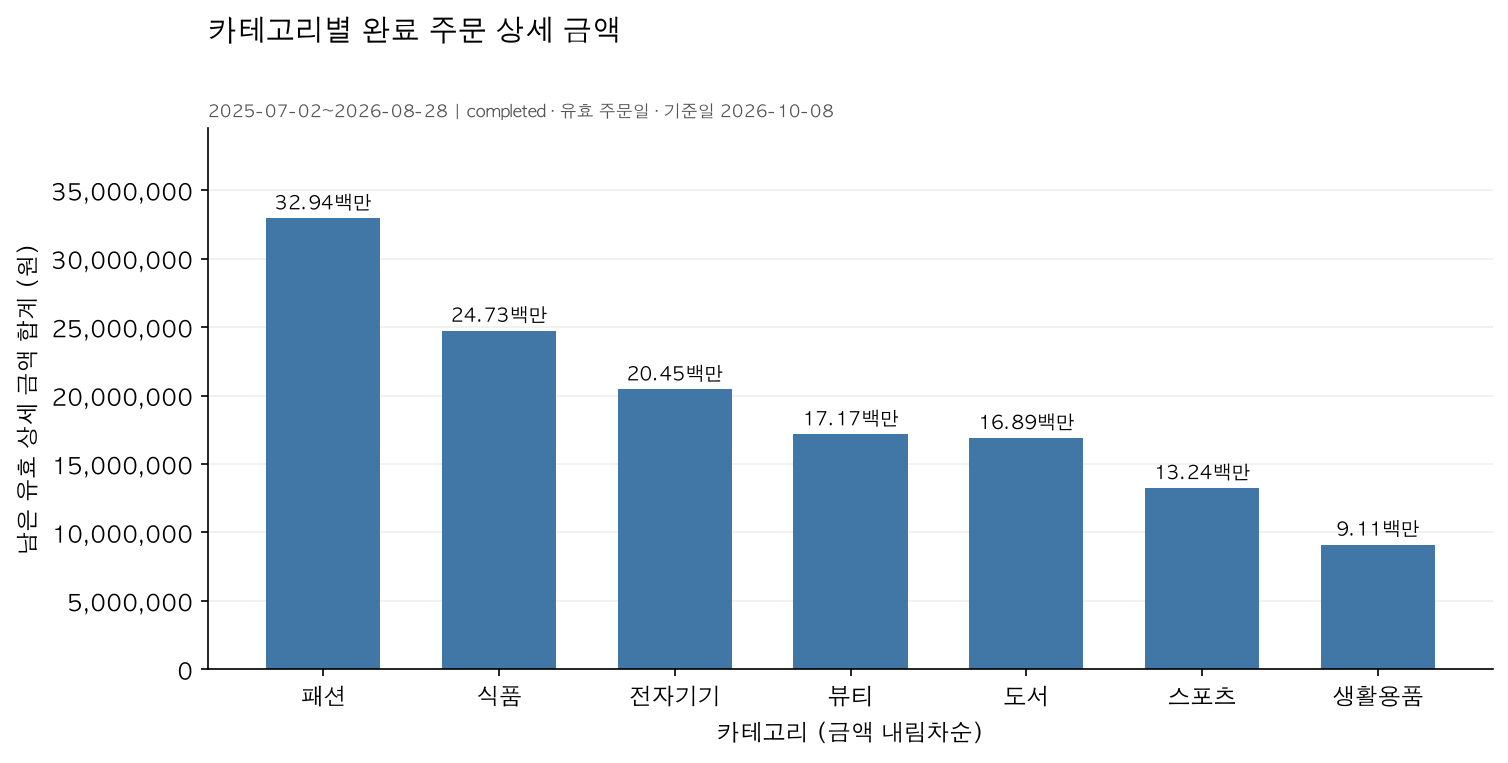

In [12]:
display(Image(filename=str(FIGURE_DIR/'graph01.png')))

**원본 집계값과 일치 여부**: 카테고리7개 막대와 집계표의7개 금액을 개별 대조했다. 총합134,523,000원이다. [저장 이미지](images/graph01.png).

**그래프에서 직접 관찰한 사실**: 패션이 가장 크고 생활용품이 가장 작다.

**나의 해석**: 남은 완료 상세 금액의 구성 차이다. 판매 수량과 거래 단가를 함께 볼 필요가 있다.

**그래프만으로 말할 수 없는 것**: 고객 선호·광고 효과·카테고리 이익의 원인을 알 수 없다.

### 그래프 2. 월별 금액 선

**그래프 선택 이유**: 월 순서에 따른 변화를 보기 위해 점이 있는 선을 선택했다. 달력 순서를 확인했고 관측 여부를 모르는 월을 임의0으로 채우지 않았다.

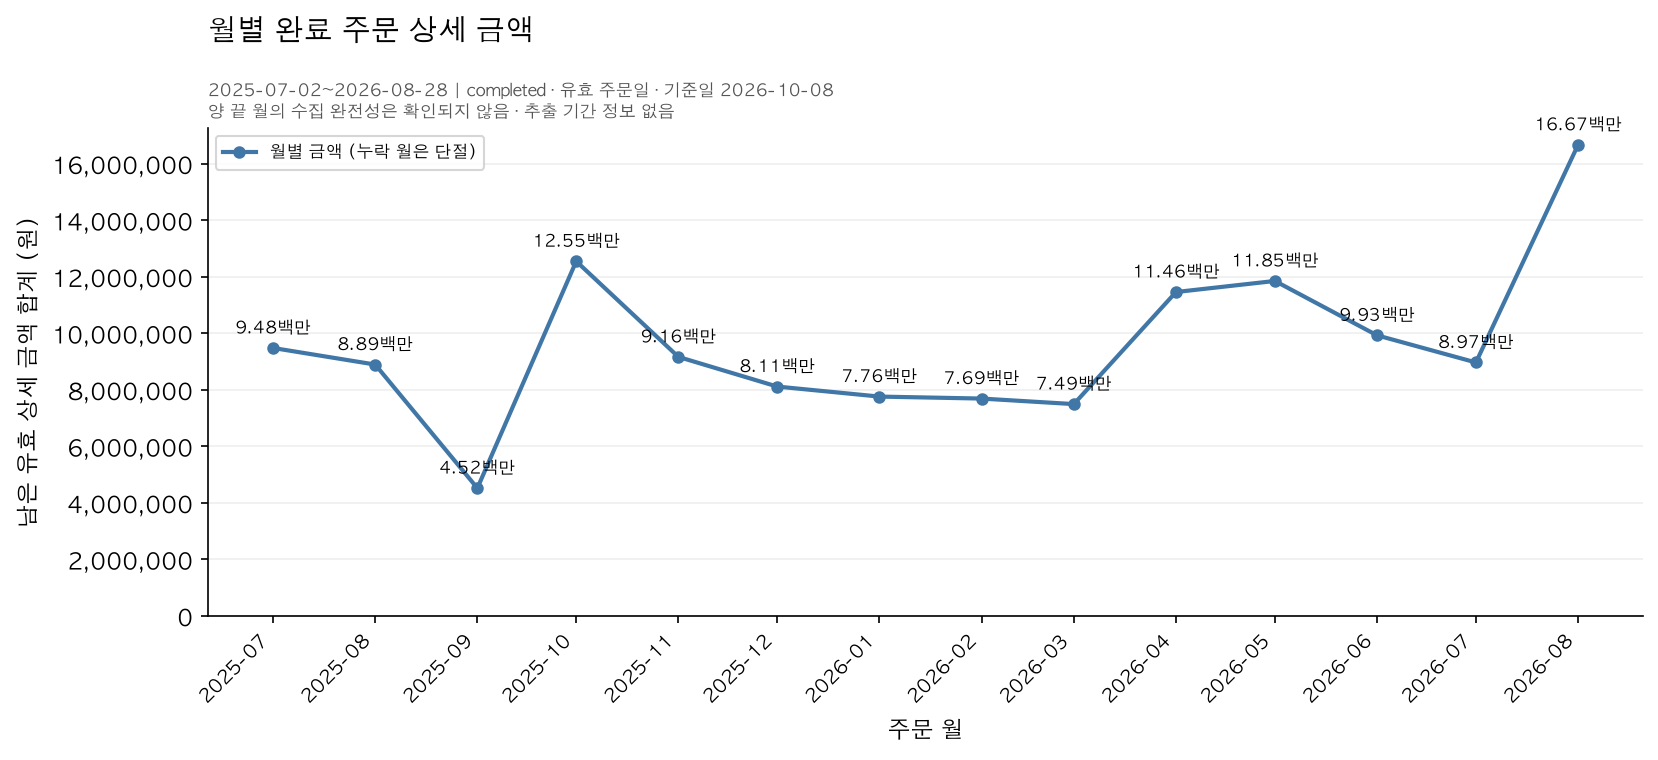

In [13]:
display(Image(filename=str(FIGURE_DIR/'graph02.png')))

**원본 집계값과 일치 여부**: 날짜 좌표와14개 월별 금액을 각각 집계표와 대조했다. 합계134,523,000원이다. [저장 이미지](images/graph02.png).

**그래프에서 직접 관찰한 사실**: 금액은 오르내렸고2026-08이 가장 크다.

**나의 해석**: 먼저 주문 수와 남은 상세 기준 평균 주문금액을 나누어 보는 것이 적절하다.

**그래프만으로 말할 수 없는 것**: 경계 월 수집 완전성, 계절성·프로모션 효과·장기 추세는 확정하지 않는다.

### 그래프 3. 금액 상위 익명 고객 가로 막대

**그래프 선택 이유**: 상위 고객 순위와 라벨을 읽기 쉽도록 가로 막대를 선택했다. 고객 라벨은 순위로 새로 만들었다.

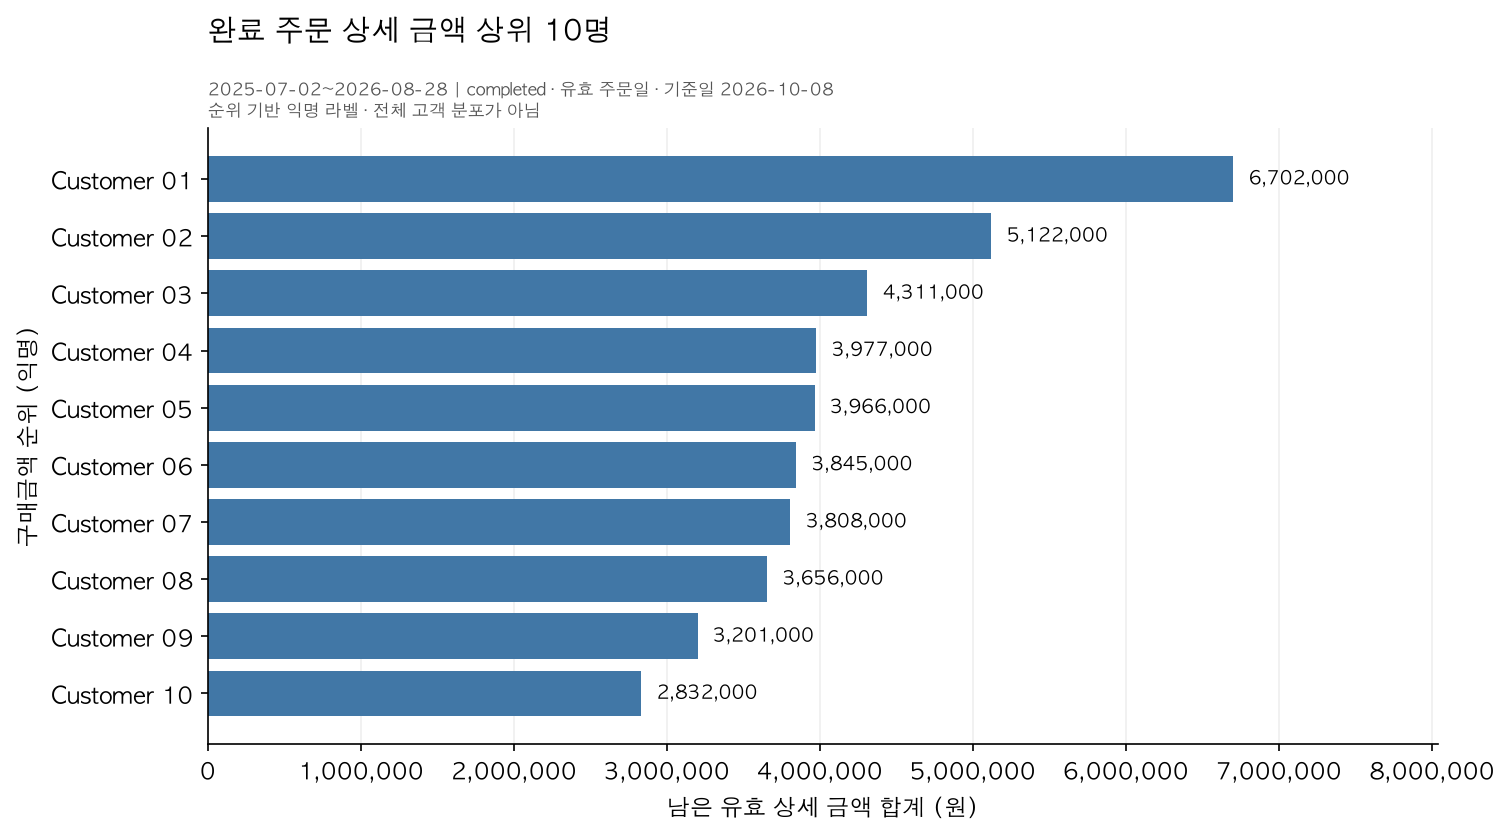

In [14]:
display(Image(filename=str(FIGURE_DIR/'graph03.png')))

**원본 집계값과 일치 여부**: Top10의 개별 막대 너비를 집계표와 대조했다. 합41,420,000원이다. [저장 이미지](images/graph03.png).

**그래프에서 직접 관찰한 사실**: Top10 안에서도 금액이 다르며, 위 표에서 모두2~6회 반복 구매임을 확인했다.

**나의 해석**: 금액 순위의 차이이며 구매 횟수·평균 표와 함께 읽어야 한다.

**그래프만으로 말할 수 없는 것**: 미래 재구매·충성도·고객 생애가치와 전체 고객 분포는 알 수 없다.

## 7. 개인정보 검증

공개 고객 결과는 `customer_label, city, order_count, total_sales, avg_order_value`만 저장한다. 이름·이메일·전화번호·주소·원본 customer_id는 포함하지 않는다. 라벨은 `Customer 01` 같은 금액 순위이며 원본 ID를 접두어만 바꿔 출력하지 않았다. 실제 저장된 CSV를 다시 읽어 확인한다.

In [15]:
saved_customer = pd.read_csv(REPORT_DIR/'ch08_customer_sales.csv')
forbidden = sorted(FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns))
print('실제 저장 고객 CSV 컬럼:', saved_customer.columns.tolist())
print('금지 컬럼:', forbidden)
assert saved_customer.columns.tolist() == PUBLIC_CUSTOMER_COLUMNS
assert not forbidden
assert saved_customer.customer_label.str.fullmatch(r'Customer [0-9]{2,}').all()
assert saved_customer.customer_label.is_unique
assert len(saved_customer) == len(customer_sales_public)
assert np.isclose(saved_customer.total_sales.sum(), customer_sales_public.total_sales.sum())
print('Privacy Gate: PASS; 저장된 익명 고객 행:', len(saved_customer))

실제 저장 고객 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
Privacy Gate: PASS; 저장된 익명 고객 행: 96


### 나의 판단

계산 내부에서 필요한 고객 ID와 공개할 결과를 구분했다. 순위 라벨은 고객의 영구 식별자가 아니어서 다음 실행·기간에서 순위가 바뀔 수 있다. 이 조치만으로 어떤 외부 정보와도 재식별이 불가능하다고 보장하지는 않는다. 원본 고객 행을 LLM 검토에 제공하지 않았다.

## 8. 최종 Validation — Evidence E06

공식 필수8항목과 추가 검증 결과를 실제 실행으로 확인한다. 처리 전 FAIL 기록은 남기고, 아래 표는 선택한 최종 범위에 대한 결과다. [최종 Validation CSV](../reports/ch08_project_validation.csv), [총합 검증 CSV](../reports/ch08_total_consistency_check.csv).

In [16]:
project_validation = project_result['project_validation']
display(project_validation)
required_checks = {'pk_integrity','fk_integrity','merge_checks_pass','line_total_consistency',
    'completed_total_consistency','category_sales_ratio_pct_sum',
    'completed_rows_with_invalid_order_date','public_customer_columns_safe'}
assert required_checks.issubset(set(project_validation['check']))
assert project_validation['status'].eq('PASS').all()
print('최종 Project Validation:', len(project_validation), '/', len(project_validation), 'PASS')

,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.00,100,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,completed_rows_after_fixed_as_of,0,0,PASS
8,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS
9,completed_scope_consistent,True,True,PASS


최종 Project Validation: 14 / 14 PASS


### FAIL이 있었다면 수정한 내용

날짜 결측을 가진 completed 상세를 월별 집계에서만 제외하면1,903,000원이 맞지 않았다. 날짜 결측과 기준일 이후 후보를 영향표에 남기고 카테고리·월·고객 모두 같은 유효 과거 거래 범위로 다시 계산했다. 원본을 고치거나 FAIL 표시만 PASS로 바꾸지 않았다. 초기 결과와 최종 결과의 범위가 다르다는 점을 함께 기록했다.

## 9. LLM 활용 기록

- 사용 목적: 질문·검증 방법·그래프·해석의 맹점 검토와 코드·문장 작성 보조.
- Safe Context: 합성 데이터 행 수와 익명 집계 요약만 제공. 원본 고객 행과 ID·연락처 미제공.
- Prompt 요약: 공통 completed 범위, 날짜 FAIL, 독립 원본 검산, 실제 그래프 값, 개인정보와 과도한 해석을 검토해 달라고 요청했다.
- 실제 응답과 요청 요약: [LLM 검토 기록](llm_review.md).

| 실제 제안 | 반영·수정·보류 | 실제 검증 근거 |
| --- | --- | --- |
| 카테고리·월·고객의 세 질문과 원본 독립 검산 | 수정 후 사용 | 원본 CSV 별도 읽기·Decimal 계산과 개별 그룹 비교. 전처리의 격리 행 번호는 공유하므로 행 선택 전체가 독립적인 검산은 아님 |
| 조건 충족176건과 금액이 있는175건 구분 | 수정 후 사용 | 상세 없는1건을 평균 분모에서 제외하고 scope표에 명시 |
| 날짜 FAIL와 금액 영향을 먼저 기록 | 수정 후 사용 | 처리 전 날짜/총합 FAIL 및 처리 후 공통 범위 PASS |
| 막대 높이·너비·선 좌표의 개별 값 대조 | 사용 | 실제 matplotlib artist 검증 결과 |
| partial18주문을 제외한 민감도 확인 | 사용 | 175주문134,523,000원과157주문120,972,000원의 실제 비교 |
| 원인·수익성·미래 고객가치 해석 | 보류 | 광고·원가·비교 설계·미래 행동 정보 없음 |
| 저장 고객 CSV 재읽기와 전체 재실행 | 사용 | Privacy Gate 및 아래 스크립트 재현 결과 |

LLM이 응답에 적은 숫자를 증거로 삼지 않고 실제 표·코드 출력과 대조했다. 코드 작성·실행·독립 검토에는 Codex의 도움을 받았으며, 별도의 학생 수동 검산을 수행했다고 쓰지 않았다.

## 10. 프로젝트 전체 재현 확인

Notebook과 터미널 스크립트가 같은 공통 함수를 사용한다. 새 프로세스로 `python scripts/run_midterm_project.py`를 실행해 이전 Notebook 메모리에 의존하지 않는지 확인한다. 기존 raw/clean8개와 생성 표·그림·보고서의 SHA-256을 대조한다.

In [17]:
def artifact_hashes():
    paths = sorted(REPORT_DIR.glob('ch08_*')) + sorted((REPORT_DIR/'figures').glob('ch08_*.png')) + sorted(FIGURE_DIR.glob('graph*.png'))
    return {str(p.relative_to(PROJECT_ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths if p.is_file()}
before = artifact_hashes()
run = subprocess.run([sys.executable,'scripts/run_midterm_project.py'], cwd=PROJECT_ROOT,
    check=True, capture_output=True, text=True)
print(run.stdout)
after = artifact_hashes()
assert before == after, 'Notebook/스크립트 산출물 해시 불일치'
current_inputs = {str(p.relative_to(PROJECT_ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
    for folder in ['raw','processed'] for p in sorted((PROJECT_ROOT/'data'/folder).glob('*.csv'))}
assert current_inputs == input_hashes, '기존 입력 CSV 변경'
saved_validation = pd.read_csv(REPORT_DIR/'ch08_project_validation.csv')
saved_total = pd.read_csv(REPORT_DIR/'ch08_total_consistency_check.csv')
assert saved_validation.status.eq('PASS').all()
assert saved_total.matches_completed.all()
for path in project_result['saved_tables']:
    assert Path(path).is_file() and Path(path).stat().st_size > 0
print('같은 실행 환경으로 전체 스크립트 종료코드:',run.returncode)
print('Notebook/스크립트 산출물 해시 일치:',len(after),'개; 기존 raw/clean 보존:',len(current_inputs),'개')
print('저장한 Validation과 total consistency 재읽기: PASS')

Chapter08 원본부터 전체 재실행 완료
작성·실행일: 2026-10-27; 고정 분석 기준일: 2026-10-08
completed 유효 상세: 421; 상세 보유 주문: 175
공통 금액: 134,523,000원; 구매고객: 96명
                                 check                value             expected status
                          pk_integrity             all PASS             all PASS   PASS
                          fk_integrity                    0                    0   PASS
                     merge_checks_pass             all PASS             all PASS   PASS
                line_total_consistency                    0                    0   PASS
           completed_total_consistency            all match            all match   PASS
          category_sales_ratio_pct_sum                100.0                  100   PASS
completed_rows_with_invalid_order_date                    0                    0   PASS
      completed_rows_after_fixed_as_of                    0                    0   PASS
          public_customer_columns_safe no forbidden columns no forbidden c

### 나의 해석과 판단

새 프로세스가 같은 원본에서 같은 결과를 만들고 파일 해시도 같았다. 이전 셀 변수나 다른 실행 순서에 기대지 않는다는 근거다. 같은 결과가 반복된다는 사실이 원천 데이터의 진실성까지 보장하지는 않으므로 키·계산식·범위·독립 검산을 함께 확인했다. [생성된 프로젝트 보고서](../reports/ch08_midterm_report.md)에 같은 기준과 결과를 정리했다.

## 11. 최종 프로젝트 요약

### 핵심 인사이트 3개

1. **패션의 완료 상세 금액 기여가 가장 컸다.** 관찰은32,940,000원·24.49%·290개다. 근거는 같은 범위의 카테고리 집계와 source 총합이다. 수량과 거래 단가를 나누어 보는 후속 비교의 출발점이지만, 원가가 없어 수익성이 높다고 말할 수 없다.
2. **최대·최소 금액 월에서 주문 수가 달랐다.** 2026-08은16,668,000원·15건, 2025-09는4,519,000원·4건이고 평균은 각각1,111,200원·1,129,750원이다. 금액만 볼 때보다 주문 수·평균을 함께 보는 것이 유용했다. 월별 원인이나 경계 월의 수집 완전성은 알 수 없다.
3. **금액 상위10명은 전체96명 금액의30.79%를 차지했고 모두2~6회 구매했다.** 고객별 고유 주문 수와 금액 표가 근거다. 평균·최근 구매일을 함께 비교할 가치가 있지만 미래 충성도나 고객 생애가치는 확정하지 않는다.

### 가장 중요한 업무·분석적 의미

같은 completed 범위를 모든 금액 결과에 적용해야 비교가 가능하다. 날짜 오류를 월별 표에서만 빠뜨린 초기 FAIL이 이를 보여 주었다. 분석 결과를 설명하기 전에 원본 독립 계산과 총합을 확인하는 과정이 필요했다.

### 현재 분석의 한계

금액은 정제 후 남은 상세 기준이고 일부 상세가 격리된18주문이 포함된다. 날짜 결측과 미래 후보를 복원하지 않았으며 경계 월 수집 완전성도 모른다. 공개 합성 데이터이므로 실제 사업의 일반적 경향으로 확대하지 않는다. 원가·할인·광고·재고가 없어 인과·순매출·이익을 계산할 수 없다.

### 다음 분석 제안

1. 원천에서 날짜 결측·미래 후보·고가 목록 가격을 확인하고, 확인 전에는 추측으로 고치지 않는다.
2. 금액 차이가 큰 월을 주문 수·평균·카테고리 구성으로 나누어 비교한다.
3. partial18주문 포함·제외 시 카테고리와 월별 결과가 얼마나 달라지는지 실제로 추가 비교한다. 이번에는 총액 민감도까지만 확인했다.

## 최종 체크

- [x] 질문·분석 대상·범위·지표·완료 기준을 먼저 정했다.
- [x] 원본4개에서 전처리부터 다시 시작했다.
- [x] 전처리 전후 행 수와 격리 사유, PK/FK·병합·계산식 근거가 있다.
- [x] 모든 금액 집계에 같은 completed·유효일·기준일 조건을 적용했다.
- [x] 원본 독립 계산과 category/month/customer 총합이 같다.
- [x] 날짜 처리 전 FAIL과 영향 금액을 숨기지 않았다.
- [x] 공개 고객 파일을 다시 읽어 직접 식별정보와 원본 ID가 없는지 검사했다.
- [x] 대표 그래프3개의 실제 값과 집계표를 대조했다.
- [x] 관찰·해석·업무 의미·한계를 분리했고 원인을 단정하지 않았다.
- [x] 최종 Validation을 확인하고 전체 스크립트를 다시 실행했다.
- [x] GitHub에서 본문·저장 출력·표·그래프·상대 링크를 확인했다.
- [x] 최종 Notebook 파일 URL의 eTL 접수를 확인했다.

실습 실행과 온라인 접수를 각각 확인했다. eTL 제출물 상세정보에는 2026-10-27 오후2:58 제출됨으로 표시되며, 제출 주소는 상단의 최종 Notebook 파일 URL이다. 채점 결과는 아직 없다.